# Radar and canopy height: what transfers

This notebook asks a practical question with real data from the Indus Delta mangroves, Pakistan: **which radar
measurement tells us how tall the canopy is?** Two very different radar products are compared:

* **Backscatter** (Sentinel-1 C-band VV and VH, PALSAR-2 L-band HH and HV): the *strength* of the echo, as in the
  first notebook.
* **Interferometric surface height**: the Copernicus DEM (GLO-30) was made by the TanDEM-X mission from the
  *phase difference* between two radar antennas flying in formation. At X-band (3 cm) the radar phase centre sits
  partly inside a canopy, so the DEM is a little higher over trees. FABDEM is the same DEM with trees and buildings
  removed by machine learning. Their difference, **DSM − DTM**, is a crude canopy height.

The reference is the lidar on the International Space Station, **GEDI**. Each GEDI footprint (25 m) records a
waveform; **RH98** is the height above the ground below which 98% of the returned energy lies, close to canopy top.

The file has 18,003 GEDI footprints (2019–2023) over the mangroves, each with the satellite values at its centre.

In [1]:
import importlib.util, os, subprocess, sys, urllib.request
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))   # silences a joblib warning on Windows
from pathlib import Path
for pkg in ("sklearn",):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn"], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110})
BASE = "https://raw.githubusercontent.com/AhmadAmmar/AhmadAmmar.github.io/main/guides/radar-python/notebooks/data_local/"
F = "indus_gedi_footprints.csv"
DATA, LOCAL = Path("data"), Path("data_local")
DATA.mkdir(exist_ok=True)
if not (DATA / F).exists():
    (DATA / F).write_bytes((LOCAL / F).read_bytes() if (LOCAL / F).exists() else urllib.request.urlopen(BASE + F, timeout=120).read())
d = pd.read_csv(DATA / F)
print(d.shape)
d.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

(18003, 15)


,mean,std,min,50%,max
lon,67.57,0.32,67.08,67.45,68.75
lat,24.30,0.35,23.71,24.28,24.82
rh50,-0.06,0.49,-1.68,-0.14,11.19
rh98,3.28,1.11,2.01,2.95,20.07
num_detectedmodes,1.03,0.19,1.00,1.00,5.00
sensitivity,0.97,0.01,0.95,0.96,1.00
s1_VV,-8.80,2.21,-22.66,-8.19,-4.00
s1_VH,-15.79,3.08,-32.00,-14.71,-12.70
s1_VH_VV,-7.00,1.47,-15.84,-6.62,-4.39
palsar_HH,-11.26,3.26,-30.87,-10.55,4.72


# First look: what GEDI sees over short mangroves

Most of these mangroves are 2–6 m tall. GEDI's laser pulse is about 15 ns long, which is a couple of metres of
height: over a short canopy the canopy echo and the ground echo **merge**. `num_detectedmodes` counts separate
peaks in the waveform; one mode means the canopy was not separated from the ground. RH98 then reports something
close to the pulse width, a **floor** that is the same whatever the trees are.

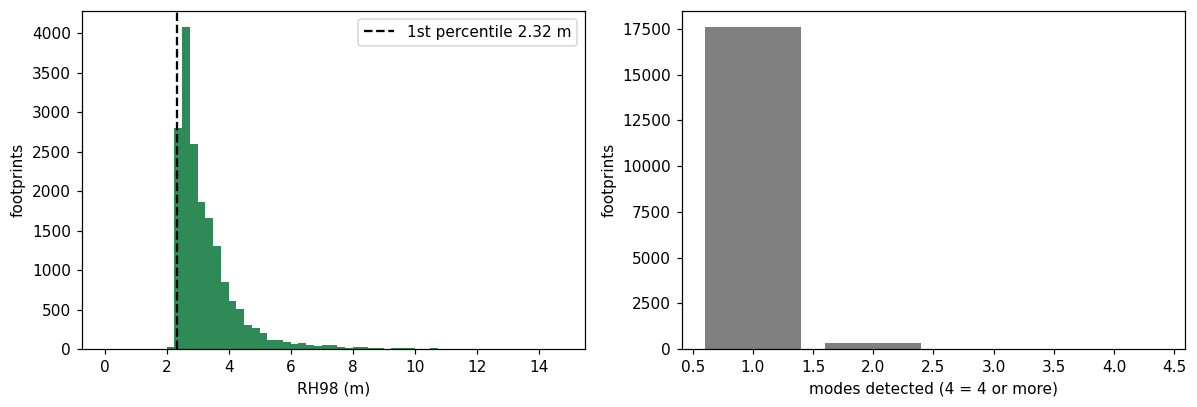

one mode: 97.7%;  RH50 below zero: 80.5%


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(d.rh98, bins=np.arange(0, 15, 0.25), color="seagreen")
ax[0].axvline(d.rh98.quantile(0.01), color="k", ls="--", label=f"1st percentile {d.rh98.quantile(0.01):.2f} m")
ax[0].set_xlabel("RH98 (m)"); ax[0].set_ylabel("footprints"); ax[0].legend()
ax[1].bar(*np.unique(d.num_detectedmodes.clip(upper=4), return_counts=True), color="grey")
ax[1].set_xlabel("modes detected (4 = 4 or more)"); ax[1].set_ylabel("footprints")
plt.tight_layout(); plt.show()
print(f"one mode: {(d.num_detectedmodes <= 1).mean():.1%};  RH50 below zero: {(d.rh50 < 0).mean():.1%}")

RH50 is below zero for most footprints: half the energy comes from at or below the ground, so RH50 says nothing
about canopy here. We use RH98 and remember that values near the floor are uninformative.

# Each radar measurement against RH98

Spearman's rank correlation, ρ, measures whether two quantities rise together, without assuming a straight line.

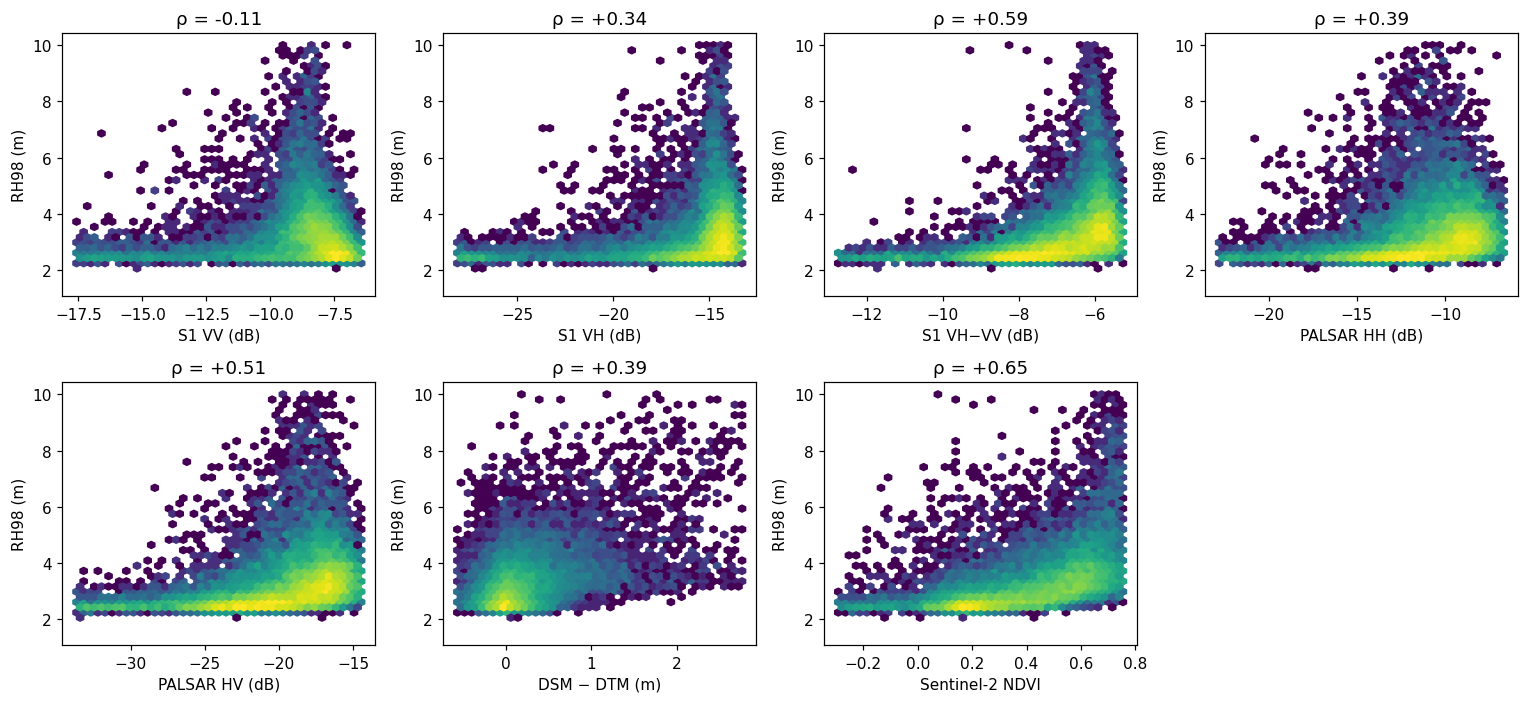

In [3]:
from scipy.stats import spearmanr
cols = {"s1_VV": "S1 VV (dB)", "s1_VH": "S1 VH (dB)", "s1_VH_VV": "S1 VH−VV (dB)", "palsar_HH": "PALSAR HH (dB)",
        "palsar_HV": "PALSAR HV (dB)", "dem_dsm_minus_dtm": "DSM − DTM (m)", "s2_NDVI_p50": "Sentinel-2 NDVI"}
rho = {c: spearmanr(d[c], d.rh98)[0] for c in cols}
fig, axs = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, (c, lab) in zip(axs.flat, cols.items()):
    ax.hexbin(d[c], d.rh98, gridsize=40, bins="log", cmap="viridis", extent=(*d[c].quantile([.01, .99]), 1.5, 10))
    ax.set_xlabel(lab); ax.set_ylabel("RH98 (m)"); ax.set_title(f"ρ = {rho[c]:+.2f}")
axs.flat[-1].axis("off"); plt.tight_layout(); plt.show()

Three things stand out. **VV alone barely relates to height** (ρ near zero): C-band co-polarised echoes come from the
top of the canopy and from the mud below, and the two change in opposite directions. **The cross-polarised ratio
VH − VV does relate** (ρ about +0.6): depolarisation grows with the volume of branches and leaves, which is why the
ratio is used as a radar vegetation index. NDVI is as strong. **DSM − DTM is noisier** than expected, because over
canopies of 2–6 m the DEM's own error (a few metres) is as large as the signal.

A correlation over the whole delta can still come from **geography** rather than physics: if the tall forest is in
one part of the delta and the radar is brighter there for another reason (soil moisture, tide, look angle), the
correlation is real but will not transfer to a new place.

# A fair test: spatial-block cross-validation

Ordinary (random) cross-validation hides a test footprint among training footprints a few tens of metres away, so a
model can succeed by **interpolating neighbours**. Here the delta is cut into 2 km cells, the cells are grouped into
five blocks by k-means on their centres, and each block is predicted by a model trained on the other four. This
measures whether a model **transfers to a region it has not seen**.

C:\Users\Owner\anaconda3\envs\eo\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Owner\anaconda3\envs\eo\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Owner\anaconda3\envs\eo\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Owner\anaconda3\envs\eo\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Owner\anaconda3\envs\eo\Lib\subprocess.py", line 1538, in _execute_child


C:\Users\Owner\anaconda3\envs\eo\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


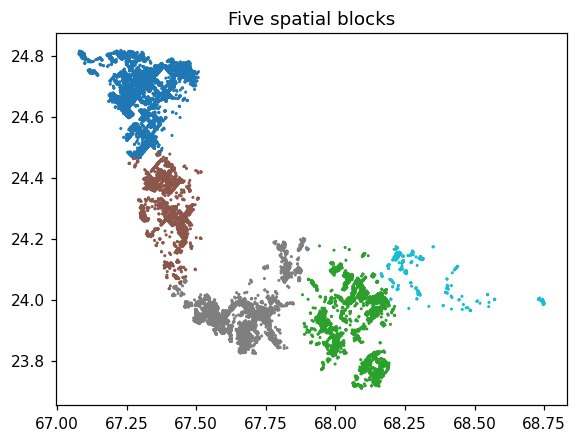

In [4]:
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

x_km = (d.lon - d.lon.min()) * 111 * np.cos(np.deg2rad(24.2)); y_km = (d.lat - d.lat.min()) * 111
cell = (x_km // 2).astype(int) * 10000 + (y_km // 2).astype(int)
cc = pd.DataFrame({"x": x_km, "y": y_km, "cell": cell}).groupby("cell").mean()
blk = pd.Series(KMeans(5, n_init=10, random_state=0).fit_predict(cc[["x", "y"]]), index=cc.index)
d["block"] = cell.map(blk).values

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(d.lon, d.lat, c=d.block, s=1, cmap="tab10"); ax.set_title("Five spatial blocks"); ax.set_aspect(1 / np.cos(np.deg2rad(24.2)))
plt.show()

In [5]:
sets = {"S1 backscatter": ["s1_VV", "s1_VH", "s1_VH_VV"], "PALSAR backscatter": ["palsar_HH", "palsar_HV"],
        "both backscatters": ["s1_VV", "s1_VH", "s1_VH_VV", "palsar_HH", "palsar_HV"],
        "interferometric height": ["dem_dsm_minus_dtm", "dem_glo30", "dem_fabdem"], "Sentinel-2 NDVI": ["s2_NDVI_p50"]}
models = {"ridge": lambda: make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 13))),
          "random forest": lambda: RandomForestRegressor(200, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=0)}
rows = []
for sname, c in sets.items():
    for mname, mk in models.items():
        for cv_name, cv, groups in (("random", KFold(5, shuffle=True, random_state=0), None), ("spatial", GroupKFold(5), d.block)):
            p = cross_val_predict(mk(), d[c], d.rh98, cv=cv, groups=groups)
            rows.append({"predictors": sname, "model": mname, "validation": cv_name, "R2": r2_score(d.rh98, p)})
res = pd.DataFrame(rows).pivot_table(index=["predictors", "model"], columns="validation", values="R2").round(2)
res["lost"] = (res.random - res.spatial).round(2)
res

validation                            random  spatial  lost
predictors             model                               
PALSAR backscatter     random forest    0.15    -0.05  0.20
                       ridge            0.12    -0.05  0.17
S1 backscatter         random forest    0.23     0.05  0.18
                       ridge            0.14    -0.01  0.15
Sentinel-2 NDVI        random forest    0.25     0.09  0.16
                       ridge            0.21     0.08  0.13
both backscatters      random forest    0.33     0.11  0.22
                       ridge            0.17     0.02  0.15
interferometric height random forest    0.35     0.10  0.25
                       ridge            0.32     0.09  0.23

Read the table in two directions:

* **Random vs spatial.** Every model loses most of its skill when regions are held out. Random folds hide a test
  footprint among neighbours a few tens of metres away, so they mostly measure interpolation.
* **Which predictors.** Under spatial blocks no group does well, and the groups are close together: backscatter
  alone is near zero, while both backscatters together, NDVI and interferometric height reach about 0.1. With most
  RH98 values on the GEDI floor, there is little real variation left to explain at the footprints.

So the footprints cannot settle which radar measurement carries canopy height. The field plots of the full study,
with measured tree heights well above the floor, can: there, three elevation predictors reached spatial-block R² of
about 0.6 for Lorey height, while Sentinel-1 and PALSAR-2 backscatter were below zero. A good reference matters as
much as a good predictor.

# Why VV falls as the canopy grows

Over open mud at low tide, C-band VV is bright. Under a closed canopy, leaves absorb and scatter the pulse before it
reaches the ground. Ground elevation (FABDEM) stands in for how often a place floods: low ground floods more often.
The next cell plots median VV by height class for four classes of ground elevation.

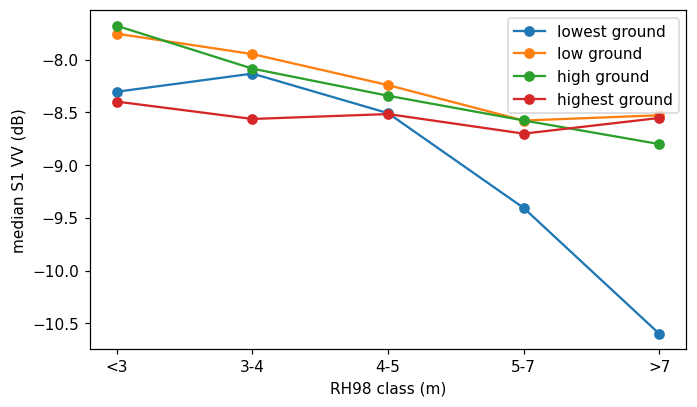

In [6]:
d["ground"] = pd.qcut(d.dem_fabdem, 4, labels=["lowest", "low", "high", "highest"])
fig, ax = plt.subplots(figsize=(7, 4))
for g, sub in d.groupby("ground", observed=True):
    b = pd.cut(sub.rh98, [0, 3, 4, 5, 7, 15])
    ax.plot(sub.groupby(b, observed=True).s1_VV.median().values, marker="o", label=f"{g} ground")
ax.set_xticks(range(5)); ax.set_xticklabels(["<3", "3-4", "4-5", "5-7", ">7"])
ax.set_xlabel("RH98 class (m)"); ax.set_ylabel("median S1 VV (dB)"); ax.legend(); plt.show()

On the lowest ground, VV drops by more than 2 dB from short to tall canopy; on the highest ground it hardly changes.
The radar's response to the same trees depends on what lies beneath them, so a model trained where the ground is low
learns a different relation from one trained where it is high. This is one reason backscatter transfers poorly.

# What to take away

1. Check what the reference really measures before modelling it: GEDI RH50 here is ground, and RH98 has a floor.
2. Test with spatial blocks when the map will be used away from the training data. Report random folds too, but call
   them interpolation.
3. Prefer predictors with a physical link to the quantity, and test them against a reference that can see the
   differences you care about. Here only the field plots could show that interferometric height transfers and
   backscatter does not.
4. A flexible model does not rescue a weak predictor; it fits the geography instead.